# SentraGrade: novelty maps that explain why an item was rejected

Grad-CAM shows where the evidence for the **guessed** class is. For a rejected item that answers the wrong question: an unseen banana gets a map of where it looks like guava. This notebook builds maps of **what looks unfamiliar** and tests whether they explain the rejection better.

**Maps compared** (all on a 16 × 16 grid of 14-pixel patches over the 224 × 224 crop):

| Map | Model | How it is made | Training |
|---|---|---|---|
| **Class-conditional novelty map (ours)** | DINOv2 ViT-S/14, frozen | Each patch is compared with stored training patches of the class the image is closest to (by its CLS token); heat = 1 − cosine similarity to the nearest such patch | none |
| Unconditional patch map (AnomalyDINO-style baseline) | DINOv2, frozen | Same, but against the pooled patches of all known classes | none |
| **Energy-CAM** | ResNet50 from the leakage notebook | Grad-CAM weights from the gradient of the energy score instead of the predicted-class logit | uses saved checkpoints |
| Grad-CAM (current explainer) | ResNet50 | Gradient of the predicted-class logit at `layer4` | uses saved checkpoints |
| Random, centre prior | none | Sanity baselines: random heat, and a Gaussian centred on the image (the fruit is usually centred) | none |

**Tests**
1. **Detection:** image-level AUROC / FPR@95 of three frozen-DINOv2 scores: CLS-prototype distance, unconditional patch score, class-conditional patch score (mean of the top 1% of patches).
2. **Faithfulness (deletion test):** cover the hottest patches step by step with the image's own background colour and track an image-level OOD score. A map that points at the real reason makes the score fall faster (lower deletion AUC). The score tracked is never the one the map is built from: the DINOv2 **CLS-prototype distance** and the ResNet **energy**.
3. **Map spread:** hot-area fraction and normalised entropy of each novelty map, saved per image for known, unknown-fruit and foreign-object images. This is the input for the spoiled / unknown / foreign triage experiment.

**Split:** the leakage-corrected time-blocked split from `leakage_split_resnet50.ipynb`, rebuilt here with the same settings. Prototypes and patch banks use **training days only**; known negatives are the **test days**.

**Kaggle setup:** inputs
- `sentragrade_data.zip` (required)
- the output zip of `leakage_split_resnet50.ipynb` (optional; enables Grad-CAM and Energy-CAM)
- a folder of foreign-object photos whose path contains the word `foreign` (optional; stones, pens, tools)

Turn on **GPU** and **Internet** (DINOv2 weights come from the Hugging Face hub through `timm`). Run All, about 20 to 40 min on a T4.

In [1]:
import os, re, glob, json, math, time, random, shutil
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.transforms.functional as TF
from torchvision.models import resnet50
from PIL import Image
from sklearn.metrics import roc_auc_score
from scipy.stats import wilcoxon
import timm
import matplotlib.pyplot as plt

# ---------------- config ----------------
SEED = 42
CLASSES = ["Banana", "Carrot", "Guava", "Indian_Gooseberry", "Mango", "Tomato"]
FOLDS = list(range(6))
SPLIT_DIRECTION, TRAIN_FRAC, BUFFER_DAYS = "forward", 0.60, 1   # must match leakage_split_resnet50.ipynb
SESSION_GAP_MIN = 5
G, PATCH = 16, 14                 # 16 x 16 patches of 14 px on a 224 crop
BANK_PER_CLASS = 30000            # training patches kept per known class
TOPK = 3                          # image score = mean of the top 1% (3 of 256) patch scores
N_DEL = 60                        # held-out images per fold used in the deletion test
DEL_STEP, DEL_MAX = 8, 128        # cover 0, 8, ..., 128 patches (up to half the image)
N_BOOT = 1000
N_FIG = 4
FILL = "background"               # how covered patches are filled: "background" (border colour) or "blur"
QUICK = False                     # True = tiny subsets for a smoke test

INPUT = Path("/kaggle/input") if Path("/kaggle/input").exists() else None
def find_data_root():
    if os.environ.get("SENTRAGRADE_DATA_ROOT"):
        return Path(os.environ["SENTRAGRADE_DATA_ROOT"])
    hits = glob.glob(f"{INPUT}/**/manifest_full.csv", recursive=True) if INPUT else []
    return Path(hits[0]).parent if hits else Path("~/sentragrade_data").expanduser()
DATA_ROOT = find_data_root()

CKPT_ROOT = os.environ.get("CKPT_ROOT", str(INPUT) if INPUT else "outputs")
CKPTS = {int(re.search(r"fold(\d)", p).group(1)): p
         for p in glob.glob(f"{CKPT_ROOT}/**/resnet50_corrected_fold*.pt", recursive=True)}

EXTS = (".jpg", ".jpeg", ".png", ".webp")
if os.environ.get("FOREIGN_DIR"):
    FOREIGN = sorted(p for p in glob.glob(os.environ["FOREIGN_DIR"] + "/**/*", recursive=True) if p.lower().endswith(EXTS))
elif INPUT:
    FOREIGN = sorted(p for p in glob.glob(f"{INPUT}/**/*", recursive=True) if "foreign" in p.lower() and p.lower().endswith(EXTS))
else:
    FOREIGN = []

OUT = Path("/kaggle/working/sentragrade_novelty") if Path("/kaggle/working").exists() else Path("outputs/sentragrade_novelty")
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
BANK_DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(SEED)
if QUICK:
    FOLDS, BANK_PER_CLASS, N_DEL, N_BOOT, N_FIG = [0], 2000, 4, 50, 2
print("data:", DATA_ROOT, "| device:", DEVICE, "| ResNet checkpoints for folds:", sorted(CKPTS), "| foreign images:", len(FOREIGN))
assert (DATA_ROOT / "manifest_full.csv").exists(), "attach sentragrade_data.zip"

data: /kaggle/input/datasets/riteesh23f3002667/sentragrade-data | device: cuda | ResNet checkpoints for folds: [0, 1, 2, 3, 4, 5] | foreign images: 0


## 1. Rebuild the leakage-corrected split

In [2]:
man = pd.read_csv(DATA_ROOT / "manifest_full.csv", dtype={"date": str, "time": str})
man["path"] = [str(DATA_ROOT / "resized" / c / f) for c, f in zip(man.class_name, man.filename)]
man["ts"] = pd.to_datetime(man.date + man.time.str.zfill(6), format="%Y%m%d%H%M%S")
man = man.sort_values(["class_name", "ts"]).reset_index(drop=True)
gap = man.groupby("class_name").ts.diff() > pd.Timedelta(minutes=SESSION_GAP_MIN)
man["session"] = man.class_name + "_" + gap.groupby(man.class_name).cumsum().astype(str)

def blocked_split(d):
    days = sorted(d.date.unique(), reverse=(SPLIT_DIRECTION == "reverse"))
    n = d.groupby("date").size().reindex(days).values
    n_tr = max(1, int((np.cumsum(n) / n.sum() <= TRAIN_FRAC).sum()))
    rest = days[n_tr + BUFFER_DAYS:]
    k = max(1, len(rest) // 2)
    return dict(train=days[:n_tr], val=rest[:k], test=rest[k:])
split_days = {c: blocked_split(d) for c, d in man.groupby("class_name")}

def get_fold(k):
    held = CLASSES[k]
    known = sorted(c for c in CLASSES if c != held)
    kn = man[man.class_name != held]
    pick = lambda part: pd.concat([kn[(kn.class_name == c) & kn.date.isin(split_days[c][part])] for c in known])
    f = dict(train=pick("train"), val=pick("val"), test=pick("test"), ood=man[man.class_name == held],
             known=known, held=held)
    if QUICK:
        f["train"] = f["train"].groupby("class_name").head(30); f["val"] = f["val"].groupby("class_name").head(10)
        f["test"] = f["test"].groupby("class_name").head(10); f["ood"] = f["ood"].head(20)
    return f

FOLD = {k: get_fold(k) for k in FOLDS}
for k, f in FOLD.items():
    print(f"fold {k} ({f['held']}): train {len(f['train'])}  val {len(f['val'])}  test {len(f['test'])}  held-out {len(f['ood'])}")

fold 0 (Banana): train 2908  val 849  test 1003  held-out 323
fold 1 (Carrot): train 2840  val 850  test 952  held-out 458
fold 2 (Guava): train 2789  val 849  test 952  held-out 510
fold 3 (Indian_Gooseberry): train 2262  val 628  test 799  held-out 1411
fold 4 (Mango): train 2890  val 866  test 952  held-out 392
fold 5 (Tomato): train 1786  val 458  test 612  held-out 2244


## 2. Frozen DINOv2 features for every image (computed once, shared by all folds)

In [3]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
                              transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class Paths(Dataset):
    def __init__(self, paths): self.paths = list(paths)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            return eval_tf(im.convert("RGB"))
def load_imgs(paths):
    return torch.stack([Paths(paths)[i] for i in range(len(paths))])

dino = timm.create_model("vit_small_patch14_dinov2.lvd142m", pretrained=True, img_size=224, num_classes=0).to(DEVICE).eval()
NPRE = dino.num_prefix_tokens
assert tuple(dino.patch_embed.grid_size) == (G, G)

@torch.no_grad()
def dino_feats(x):
    t = dino.forward_features(x.to(DEVICE))
    return F.normalize(t[:, 0].float(), dim=-1), F.normalize(t[:, NPRE:].float(), dim=-1)

need = sorted(set().union(*[set(pd.concat([f["train"], f["val"], f["test"], f["ood"]]).path) for f in FOLD.values()]))
need += [p for p in FOREIGN if p not in need]
ROW = {p: i for i, p in enumerate(need)}
CLS = np.zeros((len(need), 384), np.float32)
PT = np.zeros((len(need), G * G, 384), np.float16)
dl = DataLoader(Paths(need), batch_size=64, num_workers=NUM_WORKERS)
i0, t0 = 0, time.time()
for x in dl:
    c, p = dino_feats(x)
    CLS[i0:i0 + len(x)] = c.cpu().numpy(); PT[i0:i0 + len(x)] = p.cpu().numpy().astype(np.float16)
    i0 += len(x)
print(f"features for {len(need)} images in {time.time()-t0:.0f}s; patch array {PT.nbytes/1e9:.2f} GB")

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

features for 5338 images in 197s; patch array 1.05 GB


## 3. Patch banks, scores and maps

In [4]:
def build_bank(f):
    g = torch.Generator().manual_seed(SEED)
    protos, banks = [], []
    for c in f["known"]:
        idx = [ROW[p] for p in f["train"].path[f["train"].class_name == c]]
        protos.append(F.normalize(torch.from_numpy(CLS[idx]).mean(0), dim=0))
        P = torch.from_numpy(PT[idx].reshape(-1, 384))
        sel = torch.randperm(len(P), generator=g)[:BANK_PER_CLASS]
        banks.append(P[sel].to(DEVICE, BANK_DTYPE))
    return torch.stack(protos).to(DEVICE), banks

def score_feats(cls, pt, protos, banks):
    # cls: B x 384, pt: B x 256 x 384 (both L2-normalised)
    B = pt.shape[0]
    sim_cls = cls.to(DEVICE) @ protos.T
    cstar = sim_cls.argmax(1)                                   # class the image is closest to
    q = pt.reshape(-1, pt.shape[-1]).to(DEVICE, BANK_DTYPE)
    best = torch.stack([(q @ b.T).max(1).values.float() for b in banks], 1).reshape(B, G * G, -1)
    uncond = 1 - best.max(2).values                             # nearest patch of any known class
    cond = 1 - best.gather(2, cstar.view(B, 1, 1).expand(B, G * G, 1)).squeeze(2)   # nearest patch of class c*
    top = lambda m: m.topk(TOPK, dim=1).values.mean(1)
    return {"cls": (1 - sim_cls.max(1).values).cpu(), "uncond": top(uncond).cpu(), "cond": top(cond).cpu(),
            "map_cond": cond.reshape(B, G, G).cpu(), "map_uncond": uncond.reshape(B, G, G).cpu(), "cstar": cstar.cpu()}

def score_rows(paths, protos, banks, bs=16):
    out = []
    for s in range(0, len(paths), bs):
        idx = [ROW[p] for p in paths[s:s + bs]]
        out.append(score_feats(torch.from_numpy(CLS[idx]), torch.from_numpy(PT[idx].astype(np.float32)), protos, banks))
    return {k: torch.cat([o[k] for o in out]) for k in out[0]}

def spread(maps, tau, med):
    # hot-area fraction and normalised entropy of the excess over the typical known level
    hot = (maps > tau).float().mean((1, 2))
    ex = (maps - med).clamp(min=0).flatten(1)
    s = ex.sum(1, keepdim=True)
    p = ex / s.clamp(min=1e-12)
    ent = -(p * (p + 1e-12).log()).sum(1) / math.log(G * G)
    ent[s.squeeze(1) == 0] = 1.0
    return hot.numpy(), ent.numpy()

def fpr95(neg, pos): return float((neg >= np.percentile(pos, 5)).mean())
def boot_auroc(neg, pos, ns, ps, rng):
    a_ = pd.Series(neg).groupby(ns).apply(np.array).values; b_ = pd.Series(pos).groupby(ps).apply(np.array).values
    out = []
    for _ in range(N_BOOT):
        a = np.concatenate(a_[rng.integers(0, len(a_), len(a_))]); b = np.concatenate(b_[rng.integers(0, len(b_), len(b_))])
        out.append(roc_auc_score(np.r_[np.zeros(len(a)), np.ones(len(b))], np.r_[a, b]))
    return np.percentile(out, [2.5, 97.5])

## 4. ResNet50 Grad-CAM and Energy-CAM (only if the leakage-notebook checkpoints are attached)

In [5]:
class ResNetClassifier(nn.Module):
    def __init__(self, n):
        super().__init__()
        b = resnet50(weights=None)
        self.stem = nn.Sequential(b.conv1, b.bn1, b.relu, b.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = b.layer1, b.layer2, b.layer3, b.layer4
        self.avgpool, self.fc = b.avgpool, nn.Linear(b.fc.in_features, n)
    def forward(self, x):
        x = self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))
        f = torch.flatten(self.avgpool(x), 1)
        return self.fc(f), f

def load_resnet(k):
    if k not in CKPTS:
        return None
    ck = torch.load(CKPTS[k], map_location="cpu", weights_only=False)
    if ck.get("split_direction", "forward") != SPLIT_DIRECTION:
        print(f"WARNING fold {k}: checkpoint split_direction={ck.get('split_direction')} differs from {SPLIT_DIRECTION}")
    m = ResNetClassifier(len(ck["label_map"])); m.load_state_dict(ck["model_state_dict"])
    return m.to(DEVICE).eval()

def resnet_cams(model, x):
    acts = {}
    h = model.layer4.register_forward_hook(lambda mod, i, o: acts.__setitem__("a", o))
    with torch.enable_grad():
        logits, _ = model(x.to(DEVICE))
        A = acts["a"]
        pred = logits.argmax(1)
        g_cls, = torch.autograd.grad(logits.gather(1, pred[:, None]).sum(), A, retain_graph=True)
        energy = -torch.logsumexp(logits, 1)
        g_en, = torch.autograd.grad(energy.sum(), A)       # which channels push the energy (unfamiliarity) up
    h.remove()
    cam = lambda g: F.relu((g.mean((2, 3), keepdim=True) * A).sum(1)).detach()
    up = lambda c: F.interpolate(c[:, None], size=(G, G), mode="bilinear", align_corners=False)[:, 0].cpu()
    return up(cam(g_cls)), up(cam(g_en)), energy.detach().cpu()

@torch.no_grad()
def resnet_energy(model, x, bs=64):
    return torch.cat([-torch.logsumexp(model(x[s:s + bs].to(DEVICE))[0], 1).cpu() for s in range(0, len(x), bs)])

## 5. Deletion test

In [6]:
yy, xx = torch.meshgrid(torch.arange(G), torch.arange(G), indexing="ij")
CENTRE = torch.exp(-((yy - (G - 1) / 2) ** 2 + (xx - (G - 1) / 2) ** 2) / (2 * 4.0 ** 2))
STEPS = list(range(0, DEL_MAX + 1, DEL_STEP))
TRAPZ = getattr(np, "trapezoid", None) or np.trapz

def deletion_batch(x, heat):
    # x: 3 x 224 x 224 (normalised), heat: G x G. Returns len(STEPS) images with the hottest patches covered
    # by the image's own background colour (median of the border pixels), so covered regions look like empty belt.
    if FILL == "blur":
        fill = TF.gaussian_blur(x[None], kernel_size=51, sigma=16)[0]
    else:
        border = torch.cat([x[:, 0, :], x[:, -1, :], x[:, :, 0], x[:, :, -1]], 1)
        fill = border.median(1).values[:, None, None]
    order = heat.flatten().argsort(descending=True)
    out = []
    for n in STEPS:
        m = torch.zeros(G * G); m[order[:n]] = 1
        M = F.interpolate(m.view(1, 1, G, G), scale_factor=PATCH, mode="nearest")[0]
        out.append(x * (1 - M) + fill * M)
    return torch.stack(out)

@torch.no_grad()
def target_dino_cls(xb, protos):
    c, _ = dino_feats(xb)
    return (1 - (c @ protos.T).max(1).values).cpu()

def norm_curve(s, ref):
    # 1 = as unfamiliar as the untouched image, 0 = as familiar as a typical known test image
    return ((s - ref) / (s[0] - ref + 1e-12)).numpy()

## 6. Run every fold

In [7]:
det_rows, img_rows, del_rows, curves, fig_items = [], [], [], [], []
for k in FOLDS:
    f = FOLD[k]; t0 = time.time()
    protos, banks = build_bank(f)
    S = {part: score_rows(f[part].path.tolist(), protos, banks) for part in ["val", "test", "ood"]}
    if FOREIGN:
        S["foreign"] = score_rows(FOREIGN, protos, banks)
    rng = np.random.default_rng(SEED)
    # --- detection ---
    for m in ["cls", "uncond", "cond"]:
        neg, pos = S["test"][m].numpy(), S["ood"][m].numpy()
        lo, hi = boot_auroc(neg, pos, f["test"].session.values, f["ood"].session.values, rng)
        row = {"fold": k, "held_out": f["held"], "score": m,
               "AUROC": roc_auc_score(np.r_[np.zeros(len(neg)), np.ones(len(pos))], np.r_[neg, pos]),
               "AUROC_lo": lo, "AUROC_hi": hi, "FPR95": fpr95(neg, pos)}
        if FOREIGN:
            fo = S["foreign"][m].numpy()
            row["AUROC_vs_foreign"] = roc_auc_score(np.r_[np.zeros(len(neg)), np.ones(len(fo))], np.r_[neg, fo])
        det_rows.append(row)
    # --- per-image spread of the novelty map ---
    vm = S["val"]["map_cond"]
    tau, med = torch.quantile(vm.flatten(), 0.99).item(), vm.median().item()
    groups = [("known_test", f["test"].path.tolist(), f["test"].class_name.tolist(), "test"),
              ("unknown_fruit", f["ood"].path.tolist(), f["ood"].class_name.tolist(), "ood")]
    if FOREIGN:
        groups.append(("foreign", FOREIGN, ["Foreign"] * len(FOREIGN), "foreign"))
    for gname, paths, cls_names, part in groups:
        hot, ent = spread(S[part]["map_cond"], tau, med)
        for i, p in enumerate(paths):
            img_rows.append({"fold": k, "group": gname, "class": cls_names[i], "path": p,
                             "closest_known": f["known"][S[part]["cstar"][i]],
                             "score_cls": S[part]["cls"][i].item(), "score_uncond": S[part]["uncond"][i].item(),
                             "score_cond": S[part]["cond"][i].item(), "hot_frac": hot[i], "entropy": ent[i]})
    np.savez_compressed(OUT / f"novelty_maps_fold{k}.npz",
                        **{f"{part}_cond": S[part]["map_cond"].half().numpy() for part in S},
                        **{f"{part}_uncond": S[part]["map_uncond"].half().numpy() for part in S})
    # --- deletion test on held-out images ---
    resnet = load_resnet(k)
    del_idx = np.random.default_rng(SEED + k).choice(len(f["ood"]), size=min(N_DEL, len(f["ood"])), replace=False)
    del_paths = f["ood"].path.values[del_idx].tolist()
    X = load_imgs(del_paths)
    ref_cls = S["test"]["cls"].median()
    maps = {"novelty_cond": S["ood"]["map_cond"][del_idx], "novelty_uncond": S["ood"]["map_uncond"][del_idx],
            "random": torch.rand(len(del_idx), G, G, generator=torch.Generator().manual_seed(SEED)),
            "centre": CENTRE.expand(len(del_idx), G, G)}
    targets = {"dino_cls": lambda xb: target_dino_cls(xb, protos)}
    if resnet is not None:
        gc, ec, _ = resnet_cams(resnet, X)
        maps["gradcam"], maps["energycam"] = gc, ec
        ref_en = resnet_energy(resnet, load_imgs(f["test"].path.tolist())).median()
        targets["resnet_energy"] = lambda xb: resnet_energy(resnet, xb)
    refs = {"dino_cls": ref_cls, "resnet_energy": ref_en if resnet is not None else None}
    for i in range(len(del_idx)):
        for mname, mm in maps.items():
            batch = deletion_batch(X[i], mm[i])
            for tname, fn in targets.items():
                c = norm_curve(fn(batch), refs[tname])
                del_rows.append({"fold": k, "image": del_paths[i], "map": mname, "target": tname,
                                 "deletion_auc": float(TRAPZ(c, dx=1 / (len(c) - 1)))})
                curves.append((k, mname, tname, c))
    fig_items.append((k, f, X[:N_FIG], {m: v[:N_FIG] for m, v in maps.items()}, S["ood"]["cond"][del_idx[:N_FIG]]))
    print(f"fold {k} ({f['held']}) done in {time.time()-t0:.0f}s")
    del banks; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None

det = pd.DataFrame(det_rows); imgs = pd.DataFrame(img_rows); dele = pd.DataFrame(del_rows)
det.to_csv(OUT / "detection_per_fold.csv", index=False)
imgs.to_csv(OUT / "per_image_scores_and_spread.csv", index=False)
dele.to_csv(OUT / "deletion_per_image.csv", index=False)

fold 0 (Banana) done in 82s
fold 1 (Carrot) done in 82s
fold 2 (Guava) done in 82s
fold 3 (Indian_Gooseberry) done in 82s
fold 4 (Mango) done in 81s
fold 5 (Tomato) done in 82s


## 7. Results

In [8]:
print("Detection with frozen DINOv2 (known test days vs held-out class), mean over folds")
display(det.groupby("score").agg(AUROC=("AUROC", "mean"), AUROC_sd=("AUROC", "std"),
                                 FPR95_pct=("FPR95", lambda v: 100 * v.mean())).round(4))
display(det.round(4))

print("Deletion AUC (lower = the map points at what makes the item look unfamiliar)")
summ = dele.groupby(["target", "map"]).deletion_auc.agg(["mean", "std", "count"]).round(4)
display(summ)
summ.to_csv(OUT / "deletion_summary.csv")

tests = []
for t in dele.target.unique():
    piv = dele[dele.target == t].pivot_table(index=["fold", "image"], columns="map", values="deletion_auc")
    for a, b in [("novelty_cond", "random"), ("novelty_cond", "centre"), ("novelty_cond", "novelty_uncond"),
                 ("novelty_cond", "gradcam"), ("energycam", "gradcam"), ("energycam", "random")]:
        if a in piv and b in piv:
            d = (piv[a] - piv[b]).dropna()
            tests.append({"target": t, "map_a": a, "map_b": b, "n": len(d), "mean_diff_a_minus_b": d.mean(),
                          "a_better_share": (d < 0).mean(), "wilcoxon_p": wilcoxon(d).pvalue if len(d) > 5 else np.nan})
tests = pd.DataFrame(tests); tests.to_csv(OUT / "deletion_paired_tests.csv", index=False)
print("Paired comparisons (negative mean_diff = map_a more faithful)")
display(tests.round(4))

print("Novelty-map spread by group (input for the spoiled / unknown / foreign triage)")
display(imgs.groupby("group")[["score_cond", "hot_frac", "entropy"]].median().round(4))

Detection with frozen DINOv2 (known test days vs held-out class), mean over folds


,AUROC,AUROC_sd,FPR95_pct
score,,,
cls,0.9563,0.0509,12.3565
cond,0.8658,0.1140,25.0484
uncond,0.8535,0.1242,25.1117


,fold,held_out,score,AUROC,AUROC_lo,AUROC_hi,FPR95
0,0,Banana,cls,0.9982,0.9961,0.9996,0.0080
1,0,Banana,uncond,0.9941,0.9894,0.9977,0.0160
2,0,Banana,cond,0.9931,0.9881,0.9973,0.0259
3,1,Carrot,cls,0.9999,0.9998,1.0000,0.0000
4,1,Carrot,uncond,0.9984,0.9970,0.9996,0.0074
5,1,Carrot,cond,0.9989,0.9977,0.9997,0.0063
6,2,Guava,cls,0.9010,0.8424,0.9539,0.2479
7,2,Guava,uncond,0.8422,0.7715,0.9067,0.3225
8,2,Guava,cond,0.8648,0.7952,0.9227,0.3046
9,3,Indian_Gooseberry,cls,0.9479,0.9153,0.9759,0.2040


Deletion AUC (lower = the map points at what makes the item look unfamiliar)


mean      std  count
target        map                                   
dino_cls      centre          1.2616   0.4524    360
              energycam       1.0990   0.2222    360
              gradcam         1.2287   0.3749    360
              novelty_cond    1.1900   0.3368    360
              novelty_uncond  1.2395   0.3759    360
              random          1.0407   0.1469    360
resnet_energy centre          0.7997  14.7924    360
              energycam       0.7773   3.5477    360
              gradcam         0.7739  13.6384    360
              novelty_cond    0.4899  21.3180    360
              novelty_uncond  0.5278  21.0286    360
              random          0.5789  25.4168    360

Paired comparisons (negative mean_diff = map_a more faithful)


,target,map_a,map_b,n,mean_diff_a_minus_b,a_better_share,wilcoxon_p
0,dino_cls,novelty_cond,random,360,0.1494,0.3278,0.0000
1,dino_cls,novelty_cond,centre,360,-0.0716,0.5444,0.0021
2,dino_cls,novelty_cond,novelty_uncond,360,-0.0495,0.7222,0.0000
3,dino_cls,novelty_cond,gradcam,360,-0.0387,0.5083,0.0838
4,dino_cls,energycam,gradcam,360,-0.1298,0.5500,0.0000
5,dino_cls,energycam,random,360,0.0583,0.3639,0.0000
6,resnet_energy,novelty_cond,random,360,-0.0891,0.4806,0.0249
7,resnet_energy,novelty_cond,centre,360,-0.3099,0.5611,0.3799
8,resnet_energy,novelty_cond,novelty_uncond,360,-0.0380,0.4333,0.0041
9,resnet_energy,novelty_cond,gradcam,360,-0.2840,0.6278,0.0000


Novelty-map spread by group (input for the spoiled / unknown / foreign triage)


,score_cond,hot_frac,entropy
group,,,
known_test,0.2159,0.0117,0.8767
unknown_fruit,0.3435,0.3750,0.9742


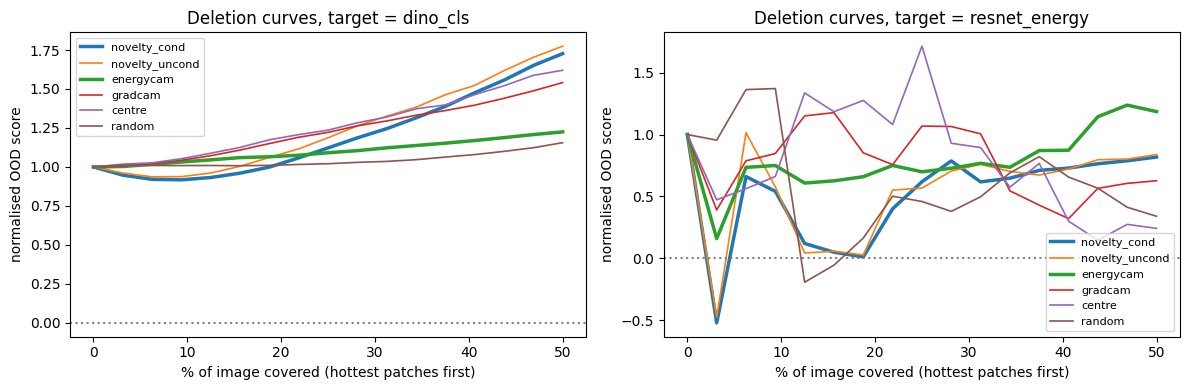

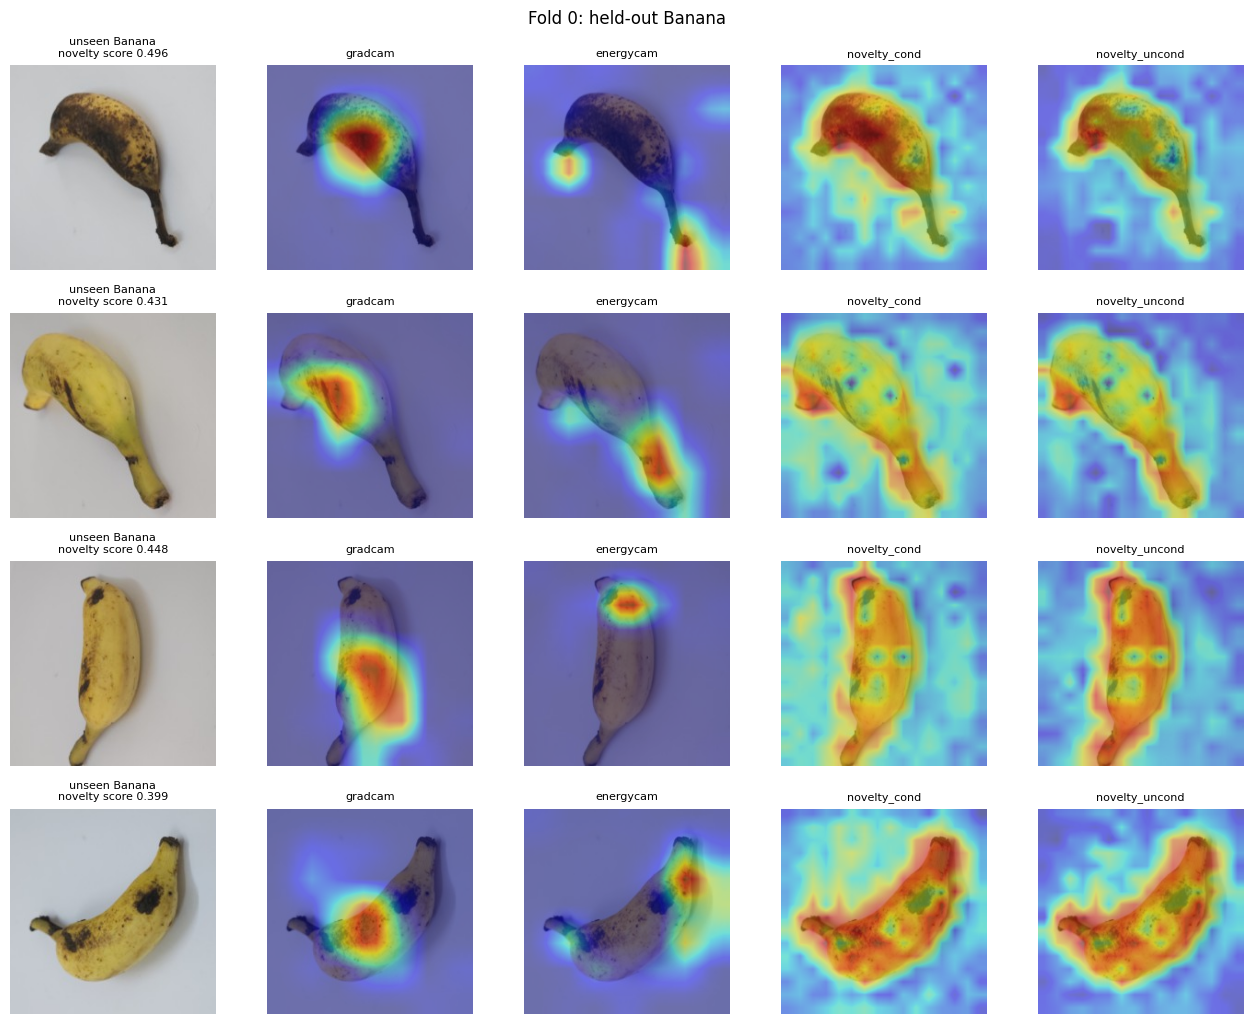

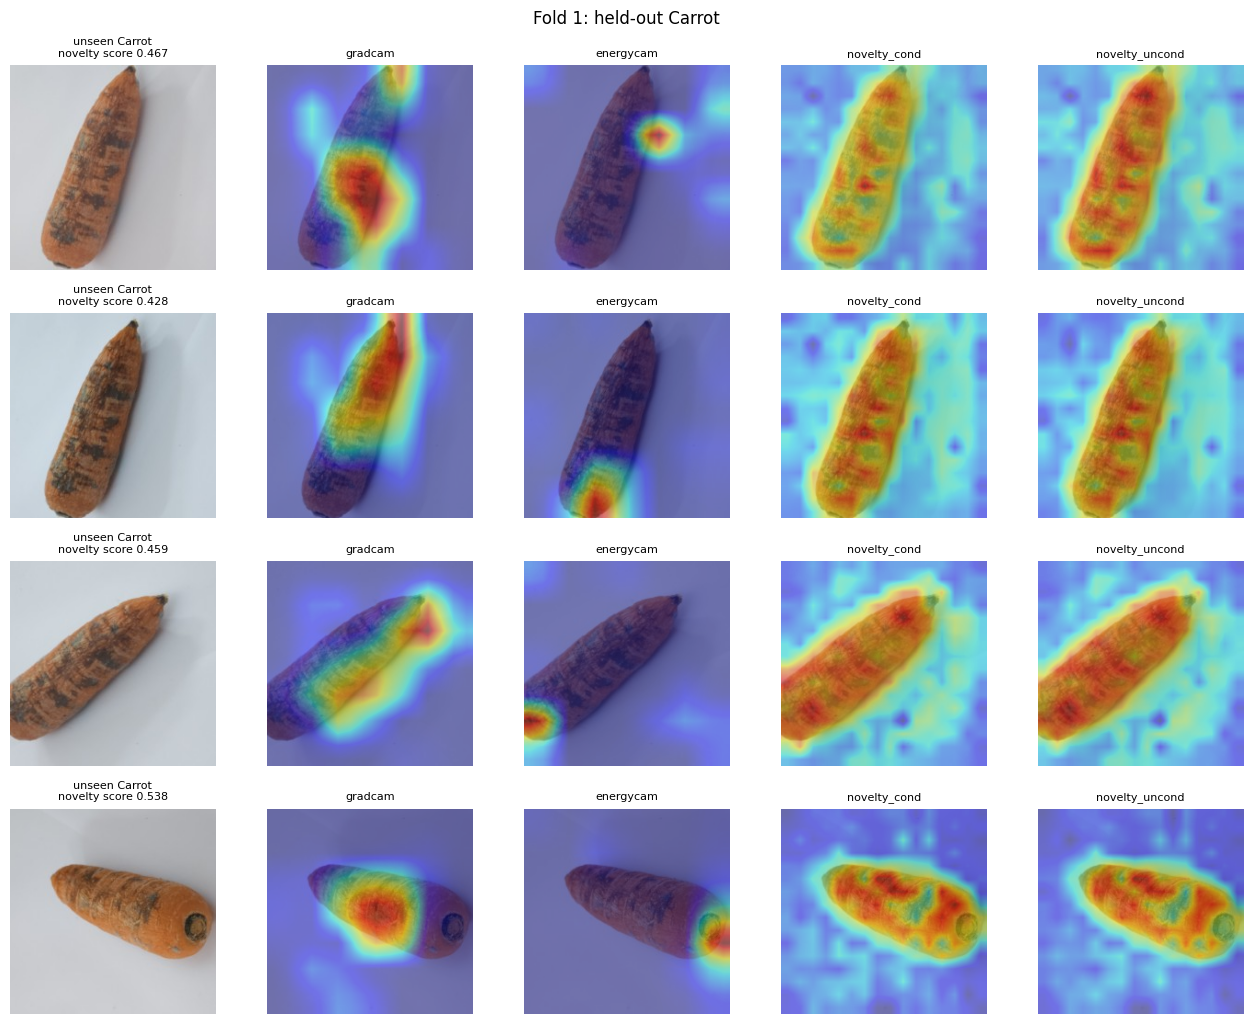

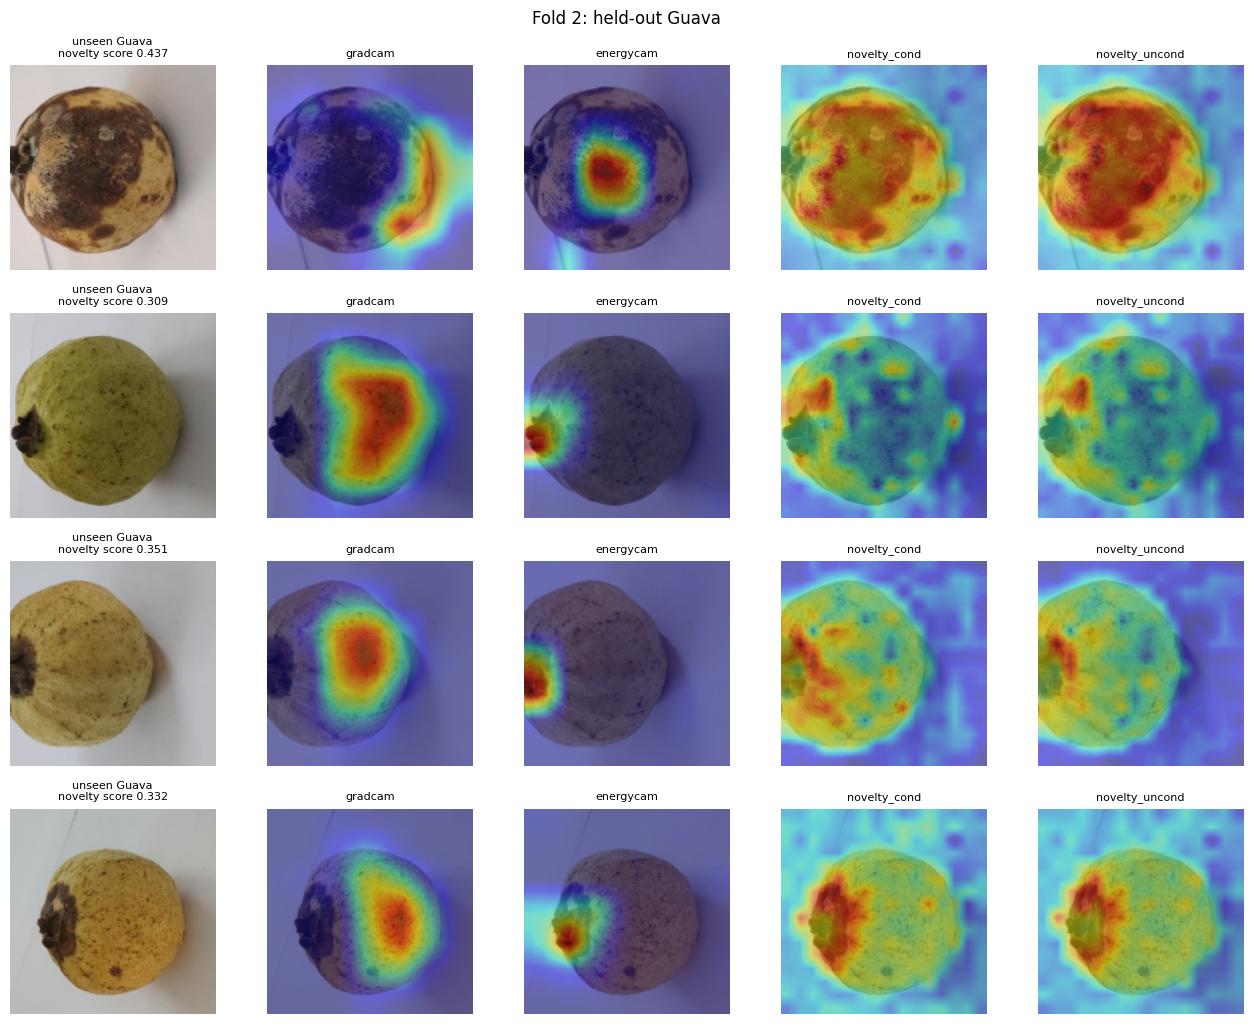

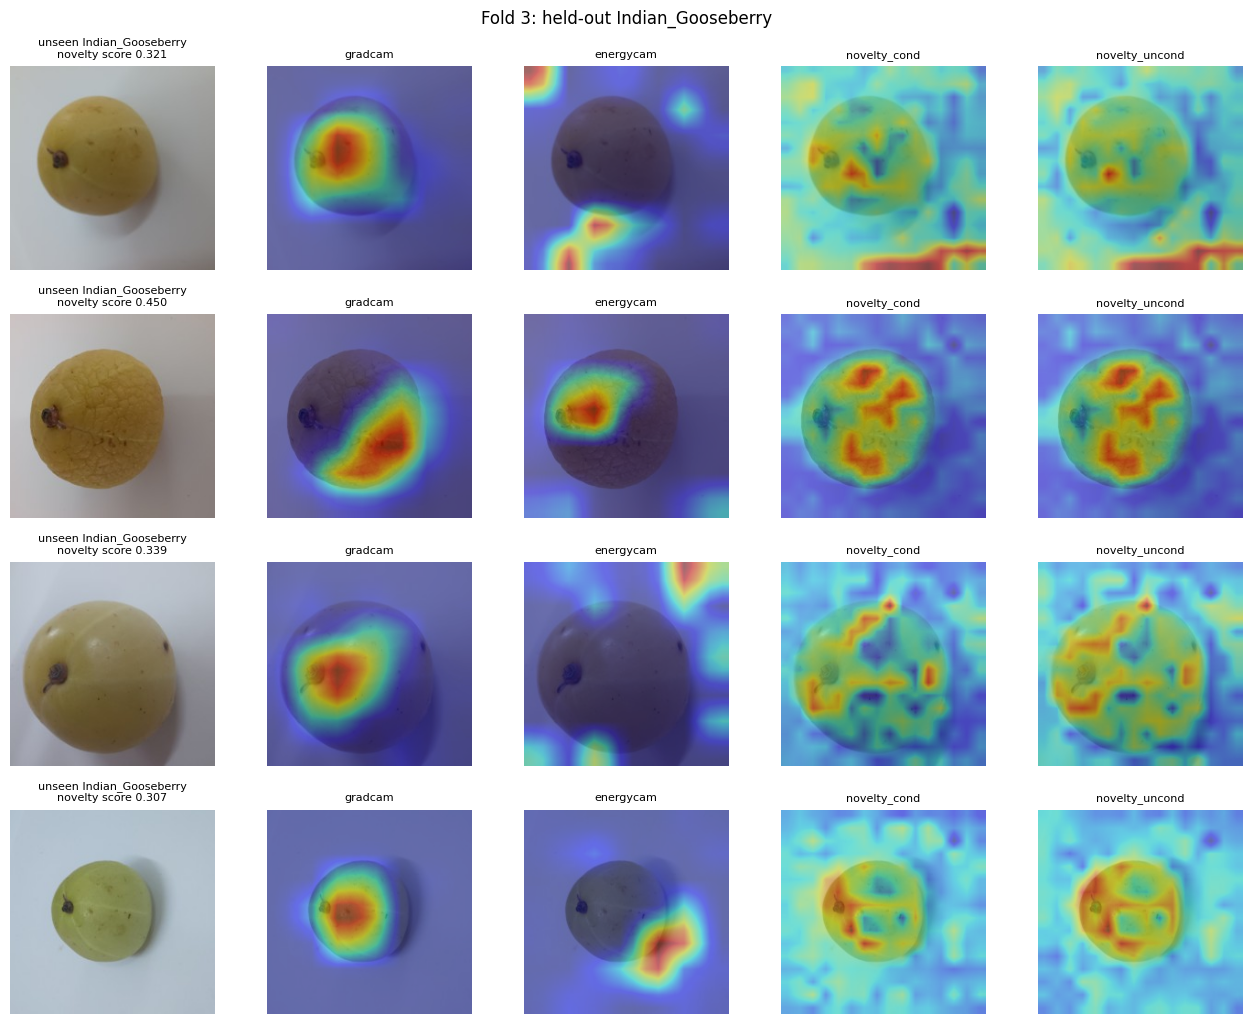

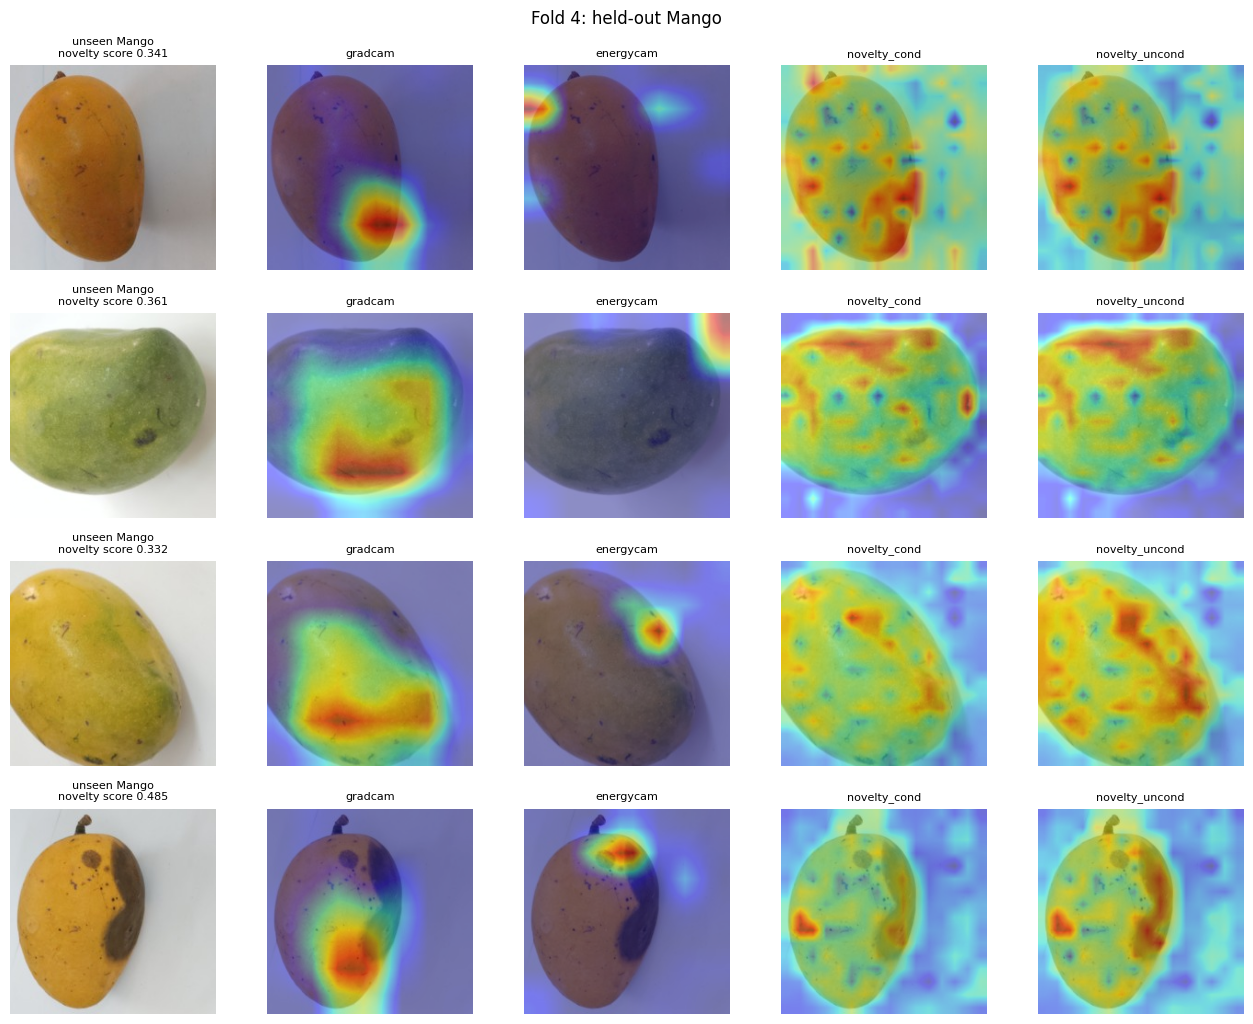

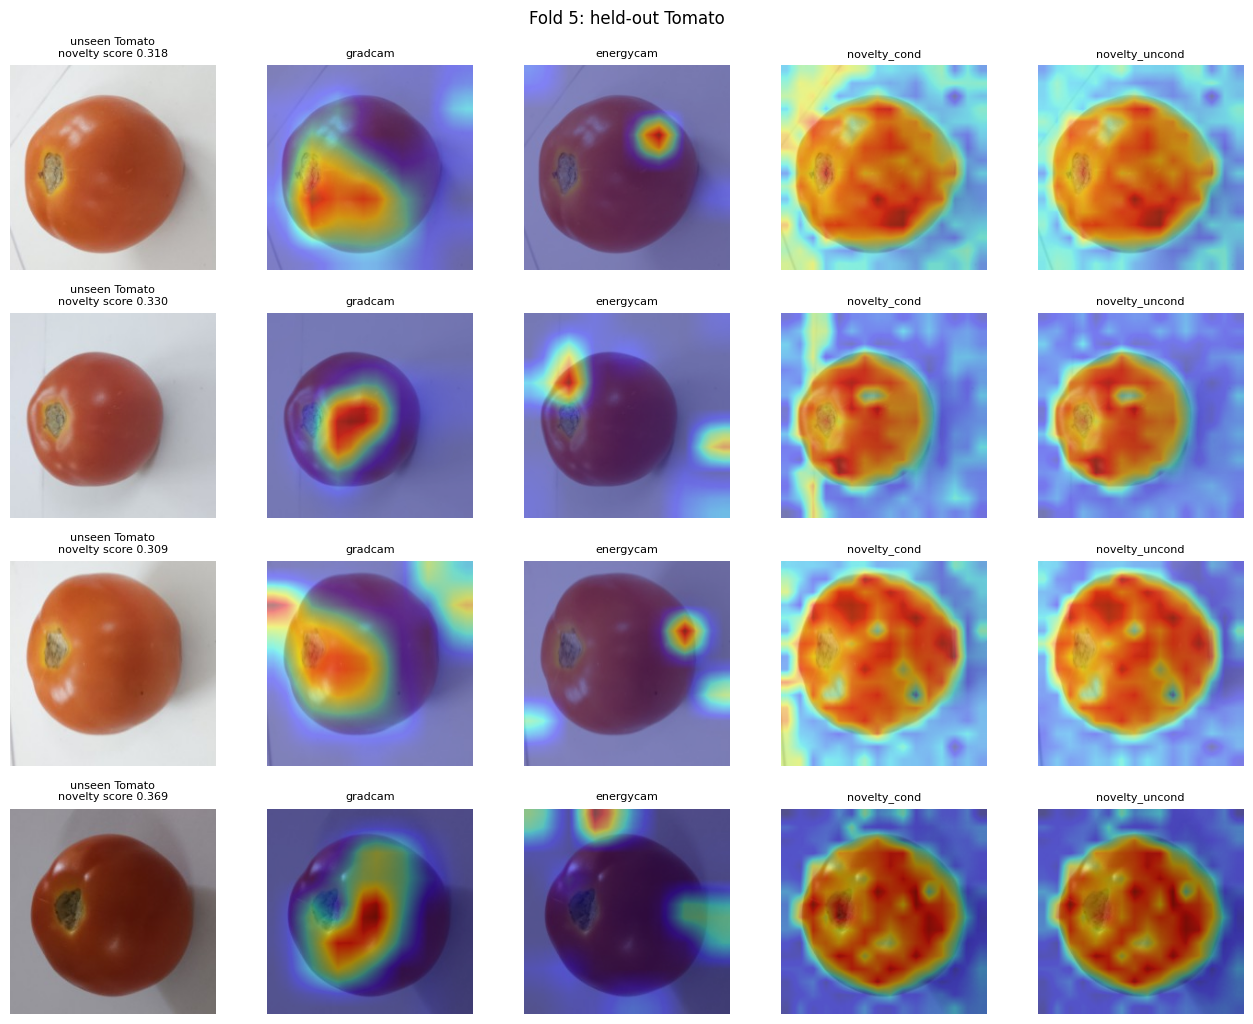

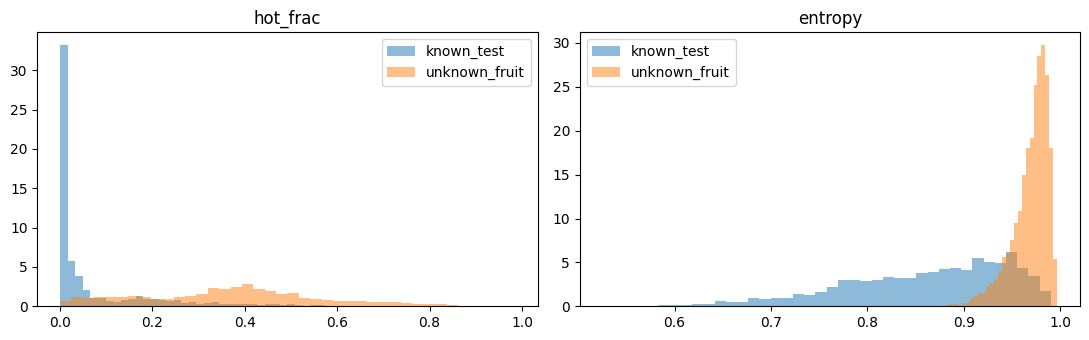

In [9]:
# deletion curves
fig, axes = plt.subplots(1, len(dele.target.unique()), figsize=(6 * len(dele.target.unique()), 4), squeeze=False)
x = np.array(STEPS) / (G * G) * 100
for ax, t in zip(axes[0], sorted(dele.target.unique())):
    for mname in ["novelty_cond", "novelty_uncond", "energycam", "gradcam", "centre", "random"]:
        cs = [c for (_, m, tt, c) in curves if m == mname and tt == t]
        if cs:
            ax.plot(x, np.mean(cs, 0), label=mname, lw=2.5 if mname in ("novelty_cond", "energycam") else 1.2)
    ax.axhline(0, color="grey", ls=":"); ax.set_xlabel("% of image covered (hottest patches first)")
    ax.set_ylabel("normalised OOD score"); ax.set_title(f"Deletion curves, target = {t}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "deletion_curves.png", dpi=200); plt.show()

# example maps per fold
def show(ax, img, heat=None, title=""):
    im = (img.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1).numpy()
    ax.imshow(im)
    if heat is not None:
        h = F.interpolate(heat[None, None].float(), size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
        h = (h - h.min()) / (h.max() - h.min() + 1e-12)
        ax.imshow(h.numpy(), cmap="jet", alpha=0.45)
    ax.set_title(title, fontsize=8); ax.axis("off")
for k, f, X, mp, sc in fig_items:
    cols = [m for m in ["gradcam", "energycam", "novelty_cond", "novelty_uncond"] if m in mp]
    fig, axes = plt.subplots(len(X), 1 + len(cols), figsize=(2.6 * (1 + len(cols)), 2.6 * len(X)), squeeze=False)
    for r in range(len(X)):
        show(axes[r, 0], X[r], title=f"unseen {f['held']}\nnovelty score {sc[r]:.3f}")
        for c, m in enumerate(cols):
            show(axes[r, c + 1], X[r], mp[m][r], m)
    plt.suptitle(f"Fold {k}: held-out {f['held']}"); plt.tight_layout()
    plt.savefig(OUT / f"maps_fold{k}.png", dpi=200); plt.show()

# spread by group
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, ["hot_frac", "entropy"]):
    for gname in imgs.group.unique():
        ax.hist(imgs[imgs.group == gname][col], bins=40, alpha=0.5, density=True, label=gname)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "spread_by_group.png", dpi=200); plt.show()

In [10]:
shutil.make_archive(str(OUT), "zip", OUT)
print("Download:", str(OUT) + ".zip")

Download: /kaggle/working/sentragrade_novelty.zip
